DATASET LOADED SUCCESSFULLY!

--- FIRST 5 ROWS ---
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]

--- LAST 5 ROWS ---
    school sex  

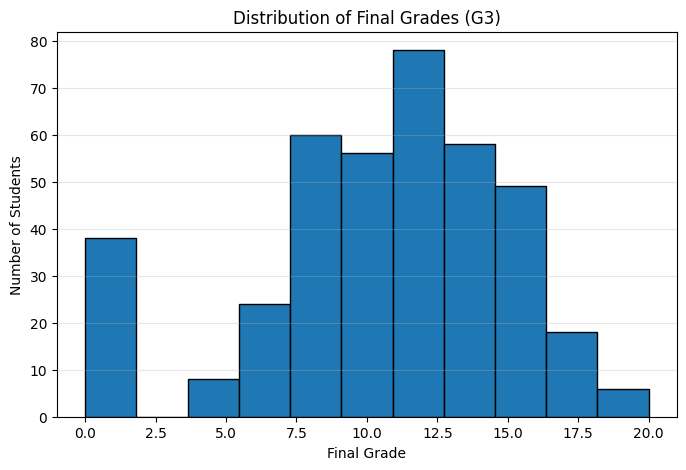

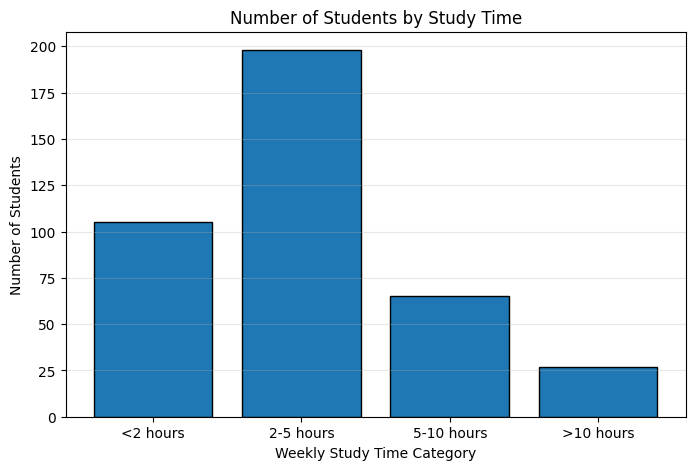


--- THREE OBSERVATIONS ---
1. Average grades:
G1 = 10.91, G2 = 10.71, G3 = 10.42

2. Gender comparison:
sex
F     9.966346
M    10.914439
Name: G3, dtype: float64

3. Study-time comparison:
studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64

--- EDA PROJECT COMPLETED SUCCESSFULLY ---


In [2]:

# ==========================================
# STUDENT PERFORMANCE - EXPLORATORY DATA ANALYSIS
# Dataset: student-mat.csv
# ==========================================

# STEP 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# STEP 2: Load dataset
# Upload student-mat.csv in Google Colab first
df = pd.read_csv('/content/student-mat.csv', sep=';')

print("DATASET LOADED SUCCESSFULLY!")

# STEP 3: Basic dataset information

print("\n--- FIRST 5 ROWS ---")
print(df.head())

print("\n--- LAST 5 ROWS ---")
print(df.tail())

print("\n--- DATASET SHAPE ---")
print(df.shape)

print("\n--- DATASET INFORMATION ---")
df.info()

print("\n--- STATISTICAL DESCRIPTION ---")
print(df.describe())

# STEP 4: Check missing values and duplicates

print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\n--- DUPLICATE RECORDS ---")
print("Total duplicates:", df.duplicated().sum())

# STEP 5: Average grades using NumPy

g1 = np.array(df['G1'])
g2 = np.array(df['G2'])
g3 = np.array(df['G3'])

print("\n--- AVERAGE GRADES ---")
print("Average G1:", np.mean(g1))
print("Average G2:", np.mean(g2))
print("Average G3:", np.mean(g3))

# STEP 6: Create grade bands using Pandas

def grade_band(grade):
    if grade < 10:
        return "Below 10"
    elif grade < 15:
        return "10-14"
    else:
        return "15-20"

df['Grade_Band'] = df['G3'].apply(grade_band)

print("\n--- STUDENT COUNT BY GRADE BAND ---")
print(df['Grade_Band'].value_counts())

# STEP 7: Compare average final grades by gender

print("\n--- AVERAGE FINAL GRADE BY GENDER ---")
print(df.groupby('sex')['G3'].mean())

# STEP 8: Compare grades by study time

print("\n--- AVERAGE FINAL GRADE BY STUDY TIME ---")
print(df.groupby('studytime')['G3'].mean())

print("\n--- STUDENT COUNT BY STUDY TIME ---")
print(df['studytime'].value_counts().sort_index())

# STEP 9: Find students with highest absences

print("\n--- TOP 10 STUDENTS BY ABSENCES ---")

top_absences = df.sort_values(
    by='absences',
    ascending=False
).head(10)

print(top_absences[['school', 'sex', 'age', 'studytime',
                    'absences', 'G1', 'G2', 'G3']])

# STEP 10: Grade histogram

plt.figure(figsize=(8, 5))

plt.hist(df['G3'], bins=11, edgecolor='black')

plt.title('Distribution of Final Grades (G3)')
plt.xlabel('Final Grade')
plt.ylabel('Number of Students')
plt.grid(axis='y', alpha=0.3)

plt.show()

# STEP 11: Study-time count chart

study_counts = df['studytime'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(study_counts.index, study_counts.values,
        edgecolor='black')

plt.title('Number of Students by Study Time')
plt.xlabel('Weekly Study Time Category')
plt.ylabel('Number of Students')

plt.xticks([1, 2, 3, 4],
           ['<2 hours', '2-5 hours',
            '5-10 hours', '>10 hours'])

plt.grid(axis='y', alpha=0.3)

plt.show()

# STEP 12: Three observations

print("\n--- THREE OBSERVATIONS ---")

print("1. Average grades:")
print(f"G1 = {np.mean(g1):.2f}, "
      f"G2 = {np.mean(g2):.2f}, "
      f"G3 = {np.mean(g3):.2f}")

gender_avg = df.groupby('sex')['G3'].mean()
print("\n2. Gender comparison:")
print(gender_avg)

study_avg = df.groupby('studytime')['G3'].mean()
print("\n3. Study-time comparison:")
print(study_avg)

print("\n--- EDA PROJECT COMPLETED SUCCESSFULLY ---")
